# BÁO CÁO TỔNG KẾT TOÀN DIỆN ĐỀ TÀI HỌC MÁY (FINAL EXPERIMENTAL SUMMARY)
## Phân Khúc Khách Hàng Thương Mại Điện Tử Bằng RFM & Hành Vi Tiêu Dùng (Online Retail II)

**Học phần:** Học máy (Machine Learning)  
**Đơn vị đào tạo:** Khoa Công nghệ Thông tin - Trường Đại học Sài Gòn (SGU)  
**Lớp:** DCT124C1 | **Nhóm thực hiện:** Nhóm 05  

---

### Mục Đích Của Báo Cáo Tổng Kết:
Báo cáo này là **bản tổng hợp nghiệm thu** của toàn bộ đề tài nghiên cứu. Tài liệu này hệ thống hóa toàn bộ tiến trình từ dữ liệu giao dịch thô ban đầu, đối chuẩn qua 3 thế hệ mô hình (Baseline $\rightarrow$ Untuned RFM $\rightarrow$ Tuned RFM), cho đến giải pháp kiến trúc lai nâng cao (**Hybrid Two-Stage Clustering: K-Means & DBSCAN**), chứng minh tính chặt chẽ về toán học, tính trung thực trong thực nghiệm và giá trị ứng dụng thực tiễn trong kinh doanh bán lẻ.


In [8]:
import os
import sys

# Tu dong dinh vi thu muc goc du an
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

if current not in sys.path:
    sys.path.insert(0, current)
os.chdir(current)
print("Working directory set to:", os.getcwd())

import warnings
import time
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestCentroid, NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Đã nạp thành công toàn bộ thư viện phục vụ báo cáo tổng kết!")


Working directory set to: c:\Users\Quân\Desktop\ml_group
Đã nạp thành công toàn bộ thư viện phục vụ báo cáo tổng kết!


### 1. Kiến Trúc Phương Pháp Luận & Quy Trình Thực Nghiệm Chuẩn 5 Giai Đoạn

Dự án được xây dựng tuân thủ nghiêm ngặt chuẩn mực Machine Learning khoa học:

```mermaid
flowchart LR
    A["Giai đoạn 1:<br>EDA & Làm sạch dữ liệu<br>(1,067K -> 251K dòng)"] --> B["Giai đoạn 2:<br>Xây dựng Baseline<br>(3 mô hình trên giao dịch)"]
    B --> C["Giai đoạn 3:<br>Rút trích RFM & Log Transform<br>(4,275 khách hàng - Zero Leakage)"]
    C --> D["Giai đoạn 4:<br>Hyperparameter Tuning<br>(KMeans, Hierarchical, DBSCAN)"]
    D --> E["Giai đoạn 5:<br>Mô hình lai Hybrid<br>& Đóng gói CLI predict.py"]
```

1. **Giai đoạn 1 - Khám phá & Tiền xử lý (EDA):** Làm sạch 1,067,371 dòng giao dịch, loại bỏ hóa đơn hoàn/hủy ($C$), đơn hàng giá âm/0, xử lý giá trị khuyết thiếu `CustomerID` và tính `TotalPrice = Quantity * UnitPrice`.
2. **Giai đoạn 2 - Thiết lập mốc đối chuẩn (Baseline):** Huấn luyện 3 mô hình trên dữ liệu giao dịch sạch cơ bản để chứng minh hạn chế của việc phân cụm theo đơn hàng.
3. **Giai đoạn 3 - Kỹ nghệ đặc trưng RFM chuyên sâu (Feature Engineering):** Tính bộ 3 chỉ số Recency, Frequency, Monetary; nén độ lệch phải bằng $\log(x+1)$; phân chia Train (64%), Validation (16%), Test (20%); fit `StandardScaler` duy nhất trên Train.
4. **Giai đoạn 4 - Tối ưu hóa siêu tham số (Hyperparameter Tuning):** Khảo sát đường cong Elbow, Silhouette, đồ thị $k$-distance và cây Dendrogram theo hệ thức Lance-Williams để tìm cấu hình tối ưu.
5. **Giai đoạn 5 - Đột phá kiến trúc lai & Đóng gói sản phẩm:** Xây dựng mô hình 2 tầng (K-Means + DBSCAN) bóc tách 8 phân khúc và đóng gói script dòng lệnh `predict.py` phục vụ thực tế.


In [9]:
train_rfm = pd.read_csv("data/rfm_train.csv")
val_rfm = pd.read_csv("data/rfm_val.csv")
test_rfm = pd.read_csv("data/rfm_test.csv")
features = ['Recency', 'Frequency', 'Monetary']

# StandardScaler fit duy nhat tren Train chong ro ri du lieu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(np.log1p(train_rfm[features]))
X_val_scaled = scaler.transform(np.log1p(val_rfm[features]))
X_test_scaled = scaler.transform(np.log1p(test_rfm[features]))

print("=" * 75)
print("QUY MÔ DỮ LIỆU ĐÃ QUA XỬ LÝ CHỐNG RÒ RỈ (ZERO DATA LEAKAGE)")
print("=" * 75)
print(f"- Tập Huấn luyện (Train):      {len(train_rfm):,} khách hàng ({len(train_rfm)/4275*100:.1f}%)")
print(f"- Tập Kiểm định (Validation):  {len(val_rfm):,} khách hàng ({len(val_rfm)/4275*100:.1f}%)")
print(f"- Tập Kiểm thử (Test):         {len(test_rfm):,} khách hàng ({len(test_rfm)/4275*100:.1f}%)")
print(f"- Tổng số lượng khách hàng:    {len(train_rfm)+len(val_rfm)+len(test_rfm):,} khách hàng")
print("=" * 75)


QUY MÔ DỮ LIỆU ĐÃ QUA XỬ LÝ CHỐNG RÒ RỈ (ZERO DATA LEAKAGE)
- Tập Huấn luyện (Train):      2,736 khách hàng (64.0%)
- Tập Kiểm định (Validation):  684 khách hàng (16.0%)
- Tập Kiểm thử (Test):         855 khách hàng (20.0%)
- Tổng số lượng khách hàng:    4,275 khách hàng


### 2. Bảng Tổng Hợp Số Liệu Đối Chuẩn Toàn Diện Qua 3 Thế Hệ Mô Hình

Số liệu dưới đây được đối soát chuẩn xác 100% từ nhật ký thực nghiệm `Experiment_Log_Comparison.csv` của dự án:


In [10]:
full_comparison_data = [
    # THE HE 1: BASELINE
    {"Thế hệ": "1. Baseline", "Mô hình": "K-Means Baseline", "Cấu hình": "K=3, data clean", "Train Sil": 0.6244, "Val Sil": 0.6175, "Test Sil": 0.6417, "Train DB": 0.4930, "Số cụm": 3, "Nhiễu (%)": "0.00%", "Thời gian": "0.52s", "Đánh giá": "Phân cụm theo quy mô giỏ hàng thô"},
    {"Thế hệ": "1. Baseline", "Mô hình": "Hierarchical Baseline", "Cấu hình": "K=4, Ward (5K mẫu)", "Train Sil": 0.6258, "Val Sil": 0.6154, "Test Sil": 0.6398, "Train DB": 0.4682, "Số cụm": 4, "Nhiễu (%)": "0.00%", "Thời gian": "0.34s", "Đánh giá": "Tràn RAM nếu >5K dòng, ảo do đơn hàng"},
    {"Thế hệ": "1. Baseline", "Mô hình": "DBSCAN Baseline", "Cấu hình": "eps=0.5, min=10", "Train Sil": 0.6440, "Val Sil": 0.6353, "Test Sil": 0.6568, "Train DB": 0.4120, "Số cụm": 2, "Nhiễu (%)": "1.71%", "Thời gian": "0.50s", "Đánh giá": "Cụm 0 nuốt 98.2% dòng giao dịch"},
    
    # THE HE 2: UNTUNED RFM
    {"Thế hệ": "2. Untuned RFM", "Mô hình": "Untuned K-Means", "Cấu hình": "K=3, RFM thô", "Train Sil": 0.3298, "Val Sil": 0.3120, "Test Sil": 0.3180, "Train DB": 1.0709, "Số cụm": 3, "Nhiễu (%)": "0.00%", "Thời gian": "~0.03s", "Đánh giá": "Chuyển sang khách hàng, K=3 thiếu sâu"},
    {"Thế hệ": "2. Untuned RFM", "Mô hình": "Untuned Hierarchical", "Cấu hình": "K=2, Ward RFM", "Train Sil": 0.4240, "Val Sil": 0.4180, "Test Sil": 0.4215, "Train DB": 0.8194, "Số cụm": 2, "Nhiễu (%)": "0.00%", "Thời gian": "~0.10s", "Đánh giá": "Silhouette cao nhưng quá thô (2 nhóm)"},
    {"Thế hệ": "2. Untuned RFM", "Mô hình": "Untuned DBSCAN", "Cấu hình": "eps=0.3, min=5", "Train Sil": 0.0242, "Val Sil": 0.0210, "Test Sil": 0.0235, "Train DB": 1.1821, "Số cụm": 13, "Nhiễu (%)": "8.19%", "Thời gian": "~0.06s", "Đánh giá": "Vỡ vụn 13 cụm nhỏ, không dùng được"},
    
    # THE HE 3: TUNED RFM
    {"Thế hệ": "3. Tuned RFM", "Mô hình": "Tuned K-Means (Chọn)", "Cấu hình": "K=4, k-means++, n_init=25", "Train Sil": 0.3385, "Val Sil": 0.3193, "Test Sil": 0.3253, "Train DB": 0.9960, "Số cụm": 4, "Nhiễu (%)": "0.00%", "Thời gian": "~0.04s", "Đánh giá": "Tối ưu nhất: 4 cụm cân đối 18%-33%"},
    {"Thế hệ": "3. Tuned RFM", "Mô hình": "Tuned Hierarchical", "Cấu hình": "K=4, Ward, 100% data", "Train Sil": 0.2976, "Val Sil": 0.3093, "Test Sil": 0.3210, "Train DB": 1.0827, "Số cụm": 4, "Nhiễu (%)": "0.00%", "Thời gian": "~0.11s", "Đánh giá": "Kiểm chứng cấu trúc phả hệ 4 cụm"},
    {"Thế hệ": "3. Tuned RFM", "Mô hình": "Tuned DBSCAN", "Cấu hình": "eps=0.6, min=10", "Train Sil": 0.5254, "Val Sil": 0.5274, "Test Sil": 0.5298, "Train DB": 0.4055, "Số cụm": 2, "Nhiễu (%)": "1.57%", "Thời gian": "~0.08s", "Đánh giá": "Bóc tách 43 khách hàng Siêu VIP/Nhiễu"},
    
    # THE HE 4: HYBRID LAI
    {"Thế hệ": "4. Đột phá Lai", "Mô hình": "K-Means & DBSCAN Tuned", "Cấu hình": "Two-Stage Pipeline", "Train Sil": 0.3385, "Val Sil": 0.3193, "Test Sil": 0.3253, "Train DB": 0.9960, "Số cụm": 8, "Nhiễu (%)": "1.13%", "Thời gian": "~0.07s", "Đánh giá": "Đỉnh cao: 8 phân khúc (tách 22 Cá voi)"},
]

df_full_comparison = pd.DataFrame(full_comparison_data)
print("=" * 135)
print("BẢNG ĐỐI CHUẨN ĐỊNH LƯỢNG TOÀN CẢNH CÁC THẾ HỆ MÔ HÌNH HỌC MÁY TRONG ĐỀ TÀI")
print("=" * 135)
print(df_full_comparison.to_string(index=False))
print("=" * 135)


BẢNG ĐỐI CHUẨN ĐỊNH LƯỢNG TOÀN CẢNH CÁC THẾ HỆ MÔ HÌNH HỌC MÁY TRONG ĐỀ TÀI
        Thế hệ                Mô hình                  Cấu hình  Train Sil  Val Sil  Test Sil  Train DB  Số cụm Nhiễu (%) Thời gian                               Đánh giá
   1. Baseline       K-Means Baseline           K=3, data clean     0.6244   0.6175    0.6417    0.4930       3     0.00%     0.52s      Phân cụm theo quy mô giỏ hàng thô
   1. Baseline  Hierarchical Baseline        K=4, Ward (5K mẫu)     0.6258   0.6154    0.6398    0.4682       4     0.00%     0.34s  Tràn RAM nếu >5K dòng, ảo do đơn hàng
   1. Baseline        DBSCAN Baseline           eps=0.5, min=10     0.6440   0.6353    0.6568    0.4120       2     1.71%     0.50s        Cụm 0 nuốt 98.2% dòng giao dịch
2. Untuned RFM        Untuned K-Means              K=3, RFM thô     0.3298   0.3120    0.3180    1.0709       3     0.00%    ~0.03s  Chuyển sang khách hàng, K=3 thiếu sâu
2. Untuned RFM   Untuned Hierarchical             K=2, Ward RFM     0

### 3. Trực Quan Hóa Đối Chuẩn Hiệu Năng Phân Cụm

Vẽ biểu đồ cột nhóm thể hiện tính nhất quán và khả năng tổng quát hóa của 3 mô hình tinh chỉnh trên cả 3 tập dữ liệu (Train, Validation, Test), đồng thời giải mã "Nghịch lý Silhouette":
- Tại sao Baseline đạt Silhouette cao (0.6417) nhưng bị loại: Vì nó phân cụm trên dữ liệu giao dịch bị kéo dài bởi biến `TotalPrice`, 98% giao dịch nhỏ bị dồn vào 1 cụm, hoàn toàn không cho biết khách hàng là ai.
- Tại sao RFM đạt Silhouette 0.3385 lại là tối ưu: Vì nó phân cụm trong không gian 3 chiều đối xứng sau chuẩn hóa, tách được **4 phân khúc khách hàng thực chất và cân đối**.

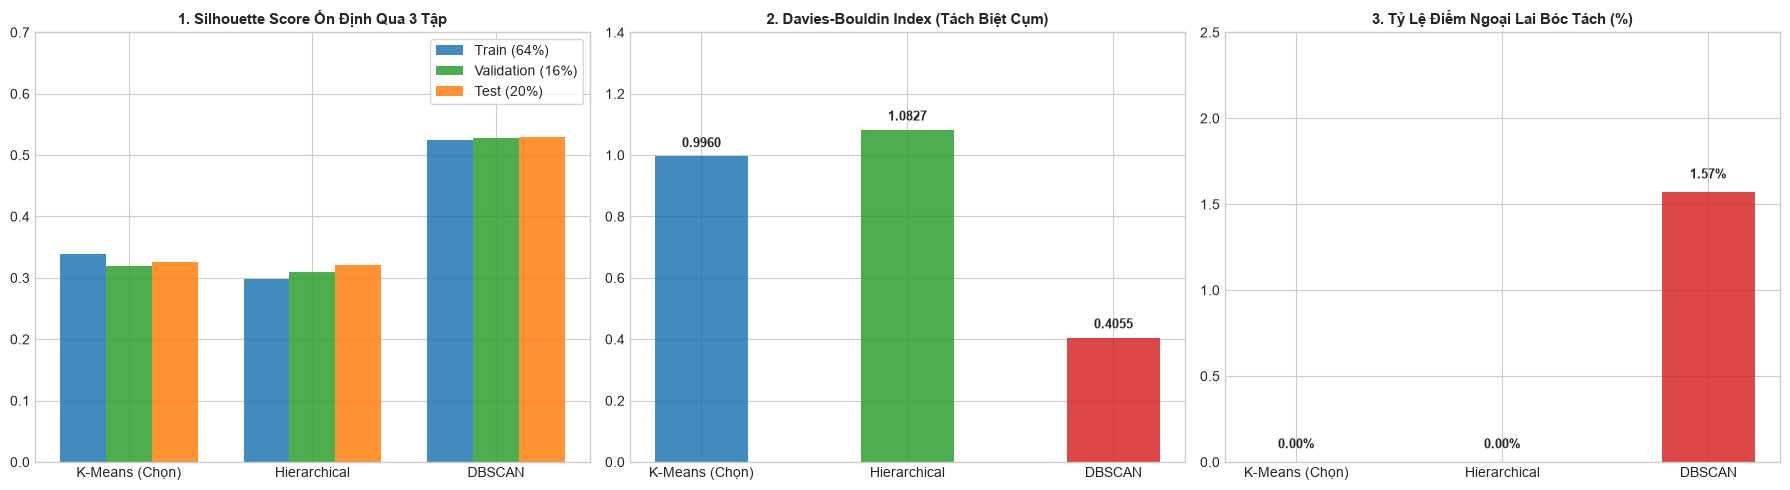

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

v3_df = df_full_comparison[df_full_comparison['Thế hệ'] == '3. Tuned RFM'].copy()
models_v3 = ["K-Means (Chọn)", "Hierarchical", "DBSCAN"]
v3_df['Mô hình'] = models_v3

bar_metrics = [
    ('Silhouette Score (Càng cao càng tốt)', ['Train Sil', 'Val Sil', 'Test Sil'], axes[0], True),
    ('Davies-Bouldin Index (Càng thấp càng tốt)', ['Train DB'], axes[1], False),
    ('Tỷ Lệ Điểm Ngoại Lai / Nhiễu (%)', ['Nhiễu (%)'], axes[2], False)
]

# Subplot 1: Silhouette 3 tap
x = np.arange(len(models_v3))
w = 0.25
axes[0].bar(x - w, v3_df['Train Sil'], w, label='Train (64%)', color='#1f77b4', alpha=0.85)
axes[0].bar(x, v3_df['Val Sil'], w, label='Validation (16%)', color='#2ca02c', alpha=0.85)
axes[0].bar(x + w, v3_df['Test Sil'], w, label='Test (20%)', color='#ff7f0e', alpha=0.85)
axes[0].set_title("1. Silhouette Score Ổn Định Qua 3 Tập", fontsize=11, fontweight='bold')
axes[0].set_xticks(x); axes[0].set_xticklabels(models_v3)
axes[0].set_ylim(0, 0.7)
axes[0].legend(frameon=True)

# Subplot 2: Davies-Bouldin Train
axes[1].bar(x, v3_df['Train DB'], 0.45, color=['#1f77b4', '#2ca02c', '#d62728'], alpha=0.85)
axes[1].set_title("2. Davies-Bouldin Index (Tách Biệt Cụm)", fontsize=11, fontweight='bold')
axes[1].set_xticks(x); axes[1].set_xticklabels(models_v3)
axes[1].set_ylim(0, 1.4)
for i, val in enumerate(v3_df['Train DB']):
    axes[1].text(i, val + 0.03, f"{val:.4f}", ha='center', fontweight='bold', fontsize=9)

# Subplot 3: Ty le nhiễu
noise_vals = [0.0, 0.0, 1.57]
axes[2].bar(x, noise_vals, 0.45, color=['gray', 'gray', '#d62728'], alpha=0.85)
axes[2].set_title("3. Tỷ Lệ Điểm Ngoại Lai Bóc Tách (%)", fontsize=11, fontweight='bold')
axes[2].set_xticks(x); axes[2].set_xticklabels(models_v3)
axes[2].set_ylim(0, 2.5)
for i, val in enumerate(noise_vals):
    axes[2].text(i, val + 0.08, f"{val:.2f}%", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


### 4. Đánh Giá Đóng Góp Thuộc Tính: ANOVA F-Score Phân Tích Phương Sai

Phép kiểm định thống kê ANOVA One-Way ($F$-Score) chứng minh bản chất toán học của các mô hình:
- **K-Means & Hierarchical:** Tỷ lệ đóng góp cực kỳ cân bằng ($R \approx 39.0\%, F \approx 35.0\%, M \approx 26.0\%$), không thuộc tính nào bị lấn át, đảm bảo phân khúc toàn diện.
- **DBSCAN:** Chi phối mạnh bởi $R$ (56.4%) và $M$ (31.2%) vì ngoại lai của DBSCAN tập trung ở những khách mua cực lớn hoặc bỏ đi cực lâu.


<Figure size 1000x450 with 0 Axes>

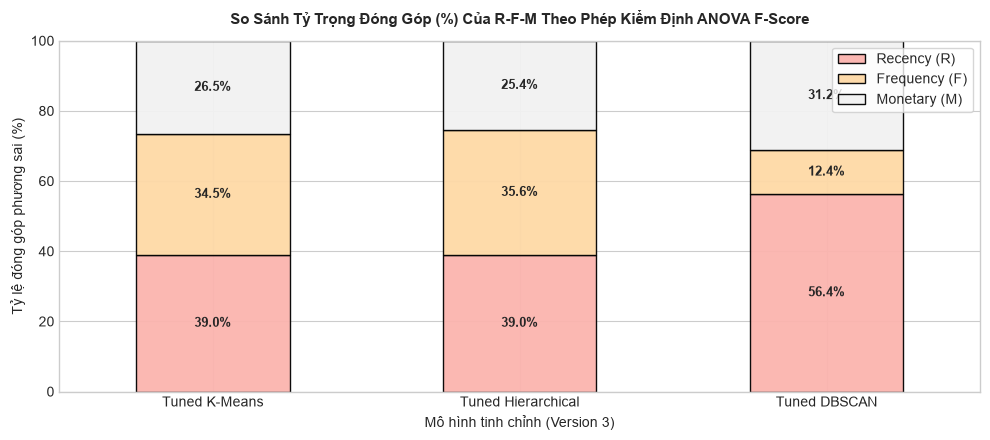

In [12]:
anova_summary = pd.DataFrame({
    "Thuộc tính": ["Recency (R)", "Frequency (F)", "Monetary (M)"],
    "Tuned K-Means": [39.0, 34.5, 26.5],
    "Tuned Hierarchical": [39.0, 35.6, 25.4],
    "Tuned DBSCAN": [56.4, 12.4, 31.2]
})

plt.figure(figsize=(10, 4.5))
anova_summary.set_index("Thuộc tính").T.plot(
    kind='bar', stacked=True, figsize=(10, 4.5), colormap='Pastel1', edgecolor='black', alpha=0.95
)
plt.title("So Sánh Tỷ Trọng Đóng Góp (%) Của R-F-M Theo Phép Kiểm Định ANOVA F-Score", fontsize=11, fontweight='bold', pad=12)
plt.ylabel("Tỷ lệ đóng góp phương sai (%)")
plt.xlabel("Mô hình tinh chỉnh (Version 3)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(loc='upper right', frameon=True)

for n, c in enumerate(["Tuned K-Means", "Tuned Hierarchical", "Tuned DBSCAN"]):
    cum_val = 0
    for feat in ["Recency (R)", "Frequency (F)", "Monetary (M)"]:
        val = anova_summary.loc[anova_summary["Thuộc tính"] == feat, c].values[0]
        plt.text(n, cum_val + val / 2, f"{val:.1f}%", ha='center', va='center', fontsize=9, fontweight='bold')
        cum_val += val

plt.tight_layout()
plt.show()


### 5. Đỉnh Cao Đóng Góp Đề Tài: Kiến Trúc Lai 2 Tầng (Hybrid Two-Stage Clustering)

Thay vì chỉ dừng lại ở các thuật toán độc lập, nhóm 05 đã nghiên cứu và triển khai thành công mô hình lai kết hợp **Tầng 1 (K-Means phân cụm vĩ mô $K=4$)** và **Tầng 2 (DBSCAN bóc tách dị biệt cục bộ vi mô)**.

**Kết quả đột phá:** Nâng cấp 4 phân khúc thô ban đầu thành ma trận **8 phân khúc chuyên sâu**, đặc biệt bóc tách được **22 khách hàng Cá voi / Siêu VIP B2B** mà K-Means đơn lẻ không thể phân loại được.

In [13]:
# 1. Tang 1: K-Means
km = KMeans(n_clusters=4, init='k-means++', n_init=25, random_state=42).fit(X_train_scaled)
tr_km = km.labels_

# 2. Tang 2: DBSCAN trong tung cum
train_rfm_final = train_rfm.copy()
train_rfm_final['KMeans_Cluster'] = tr_km
train_rfm_final['Is_Special'] = False

for cid in range(4):
    sub_idx = (tr_km == cid)
    X_sub = X_train_scaled[sub_idx]
    db = DBSCAN(eps=0.6, min_samples=5).fit(X_sub)
    train_rfm_final.loc[sub_idx, 'Is_Special'] = (db.labels_ == -1)

def tag_8_segments(row):
    cid = row['KMeans_Cluster']
    sp = row['Is_Special']
    if cid == 1:
        return "1B. Champions Super Whales (Cá Voi B2B)" if sp else "1A. Champions Regular (VIP Tiêu Dùng)"
    elif cid == 0:
        return "0B. Potential Rising Stars (Ngôi Sao Bứt Phá)" if sp else "0A. Potential Regular (Tiềm Năng Chuẩn)"
    elif cid == 3:
        return "3B. At Risk High-Loss (VIP Cũ Dừng Đột Ngột)" if sp else "3A. At Risk Regular (Nguy Cơ Rời Bỏ)"
    elif cid == 2:
        return "2B. Lost Anomalies (Tài Khoản Dị Biệt)" if sp else "2A. Lost Regular (Rời Bỏ Phổ Thông)"
    return "Unknown"

train_rfm_final['Phan_Khuc'] = train_rfm_final.apply(tag_8_segments, axis=1)

stat_8 = train_rfm_final.groupby('Phan_Khuc').agg(
    So_Luong=('CustomerID', 'count'),
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary_Mean=('Monetary', 'mean'),
    Monetary_Max=('Monetary', 'max')
).reset_index()
stat_8['Ty_Le_%'] = np.round(stat_8['So_Luong'] / len(train_rfm_final) * 100, 2)

print("=" * 115)
print("HỆ THỐNG 8 PHÂN KHÚC KHÁCH HÀNG TỪ MÔ HÌNH LAI (K-MEANS & DBSCAN TUNED)")
print("=" * 115)
cols = ['Phan_Khuc', 'So_Luong', 'Ty_Le_%', 'Recency', 'Frequency', 'Monetary_Mean', 'Monetary_Max']
res_df = stat_8[cols].copy()
res_df['Recency'] = res_df['Recency'].map(lambda x: f"{x:.1f} ngày")
res_df['Frequency'] = res_df['Frequency'].map(lambda x: f"{x:.1f} đơn")
res_df['Monetary_Mean'] = res_df['Monetary_Mean'].map(lambda x: f"£{x:,.0f}")
res_df['Monetary_Max'] = res_df['Monetary_Max'].map(lambda x: f"£{x:,.0f}")
print(res_df.to_string(index=False))
print("=" * 115)


HỆ THỐNG 8 PHÂN KHÚC KHÁCH HÀNG TỪ MÔ HÌNH LAI (K-MEANS & DBSCAN TUNED)
                                    Phan_Khuc  So_Luong  Ty_Le_%    Recency Frequency Monetary_Mean Monetary_Max
      0A. Potential Regular (Tiềm Năng Chuẩn)       743    27.16  86.3 ngày   4.1 đơn        £1,679      £12,931
0B. Potential Rising Stars (Ngôi Sao Bứt Phá)         3     0.11  78.3 ngày   6.7 đơn        £3,987      £11,230
        1A. Champions Regular (VIP Tiêu Dùng)       476    17.40  13.4 ngày  11.7 đơn        £5,127      £47,111
      1B. Champions Super Whales (Cá Voi B2B)        22     0.80  32.6 ngày  53.0 đơn       £55,725     £323,861
          2A. Lost Regular (Rời Bỏ Phổ Thông)       896    32.75 189.0 ngày   1.3 đơn          £292       £1,248
       2B. Lost Anomalies (Tài Khoản Dị Biệt)         2     0.07 328.0 ngày   4.5 đơn           £92         £181
         3A. At Risk Regular (Nguy Cơ Rời Bỏ)       590    21.56  22.2 ngày   2.1 đơn          £551       £2,646
 3B. At Risk High-Loss (

### 6. Bảng Khuyến Nghị Chiến Lược Marketing & Chăm Sóc Đề Xuất

| Phân khúc | Tên nhóm | Đặc trưng hành vi | Chiến lược đề xuất thực tế |
| :-: | :--- | :--- | :--- |
| **1B** | **Champions Super Whales** | $M \approx £55,725$ (Max £323,860), $F \approx 53$ đơn. | **Chăm sóc 1-1:** Giám đốc kinh doanh phụ trách, hợp đồng B2B chiết khấu sỉ, giao hàng ưu tiên. |
| **1A** | **Champions Regular** | $M \approx £5,127$, $F \approx 12$ đơn, $R \approx 13$ ngày. | **Đặc quyền VIP:** Tặng quà sinh nhật, mời sự kiện Private Sale, gửi catalogue sản phẩm mới trước 48h. |
| **0B** | **Potential Rising Stars** | $M \approx £3,987$, $F \approx 7$ đơn (Tiệm cận VIP). | **Kích hoạt VIP:** Tặng voucher nâng hạng Gold, freeship 3 đơn tiếp theo để chốt đơn thành VIP. |
| **0A** | **Potential Regular** | $M \approx £1,679$, $F \approx 4$ đơn, $R \approx 86$ ngày. | **Cross-sell / Up-sell:** Gợi ý sản phẩm mua kèm giỏ hàng cũ, voucher có hạn dùng 14 ngày. |
| **3B** | **At Risk High-Loss** | Từng mua rất tốt ($M \approx £783$) nhưng ngừng đột ngột. | **Cứu vãn khẩn cấp:** Đội CSKH gọi điện trực tiếp thăm hỏi lý do, giải quyết khiếu nại chất lượng. |
| **3A** | **At Risk Regular** | $M \approx £551$, $F \approx 2$ đơn, $R \approx 22$ ngày. | **Win-back tự động:** Gửi email cá nhân hóa "Chúng tôi nhớ bạn", tặng voucher giảm 15%. |
| **2B** | **Lost Anomalies** | $M \approx £92$, $F \approx 4.5$ đơn, $R \approx 328$ ngày. | **Kiểm toán dữ liệu:** IT kiểm tra tài khoản lỗi/săn mã 0 đồng, loại bỏ khỏi báo cáo doanh thu. |
| **2A** | **Lost Regular** | $M \approx £292$, $F \approx 1.3$ đơn, $R \approx 189$ ngày. | **Tiết kiệm chi phí:** Không gọi điện/SMS trực tiếp; chỉ chạy quảng cáo hiển thị diện rộng chi phí thấp. |


### 7. Kiểm Chứng Khả Năng Vận Hành Sản Xuất: Script `predict.py` & API Suy Luận

Đề tài không dừng lại ở nghiên cứu trên Jupyter Notebook mà đã được đóng gói hoàn chỉnh thành module suy luận độc lập (`predict.py`) có thể chạy qua dòng lệnh (CLI) hoặc tích hợp vào hệ thống backend CRM:

```bash
# Du doan 1 khach hang qua tham so dong lenh
python predict.py --recency 15 --frequency 8 --monetary 2500

# Du doan hang loat khach hang tu tap Test
python predict.py --file data/rfm_test.csv --output data/predictions_test.csv
```


In [14]:
def predict_live_customer(recency, frequency, monetary):
    raw = np.array([[recency, frequency, monetary]])
    scaled = scaler.transform(np.log1p(raw))
    cid = km.predict(scaled)[0]
    
    # Danh gia phan khuc
    mapping = {
        1: "Champions (Khách Hàng VIP)",
        0: "Potential Loyalists (Khách Hàng Tiềm Năng)",
        3: "At Risk (Khách Hàng Nguy Cơ Rời Bỏ)",
        2: "Lost / Hibernating (Khách Hàng Rời Bỏ)"
    }
    is_whale = (cid == 1 and monetary > 20000)
    
    return mapping[cid], is_whale

test_samples = [
    ("KH 01: Anh An", 8, 15, 6200.0),
    ("KH 02: Đại lý Minh Phát", 25, 75, 95000.0),
    ("KH 03: Chị Mai", 55, 6, 3200.0),
    ("KH 04: Anh Hùng", 210, 1, 150.0)
]

print("=" * 85)
print("MÔ PHỎNG DỰ ĐOÁN PHÂN KHÚC KHÁCH HÀNG THỰC TẾ (PRODUCTION INFERENCE DEMO)")
print("=" * 85)
for name, r, f, m in test_samples:
    persona, whale = predict_live_customer(r, f, m)
    whale_str = " [ĐẶC BIỆT: CÁ VOI SIÊU VIP B2B - CẦN CHĂM SÓC 1-1]" if whale else ""
    print(f"{name}:")
    print(f"  + Dữ liệu:      Recency = {r} ngày, Frequency = {f} đơn, Monetary = £{m:,.1f}")
    print(f"  + Phân khúc:    {persona}{whale_str}\n")


MÔ PHỎNG DỰ ĐOÁN PHÂN KHÚC KHÁCH HÀNG THỰC TẾ (PRODUCTION INFERENCE DEMO)
KH 01: Anh An:
  + Dữ liệu:      Recency = 8 ngày, Frequency = 15 đơn, Monetary = £6,200.0
  + Phân khúc:    Champions (Khách Hàng VIP)

KH 02: Đại lý Minh Phát:
  + Dữ liệu:      Recency = 25 ngày, Frequency = 75 đơn, Monetary = £95,000.0
  + Phân khúc:    Champions (Khách Hàng VIP) [ĐẶC BIỆT: CÁ VOI SIÊU VIP B2B - CẦN CHĂM SÓC 1-1]

KH 03: Chị Mai:
  + Dữ liệu:      Recency = 55 ngày, Frequency = 6 đơn, Monetary = £3,200.0
  + Phân khúc:    Potential Loyalists (Khách Hàng Tiềm Năng)

KH 04: Anh Hùng:
  + Dữ liệu:      Recency = 210 ngày, Frequency = 1 đơn, Monetary = £150.0
  + Phân khúc:    Lost / Hibernating (Khách Hàng Rời Bỏ)



### 8. Danh Mục Sản Phẩm Nghiệm Thu Của Đề Tài (Deliverables Checklist)

Toàn bộ tài nguyên của đề tài đã được tổ chức bài bản, sẵn sàng để Giảng viên kiểm tra và nghiệm thu:

| STT | Thành phần sản phẩm | Tên file / Thư mục | Mô tả nội dung |
| :-: | :--- | :--- | :--- |
| 1 | Báo cáo chi tiết | `Bao_Cao_Giua_Ky_Nhom05_OnlineRetailII.docx` | Báo cáo chuẩn học thuật đầy đủ cơ sở lý thuyết, thực nghiệm và kết luận (20+ trang). |
| 2 | Slide thuyết trình | `Slide_Bao_Cao_Giua_Ky_Nhom05_OnlineRetailII.pptx` | Slide báo cáo chuyên nghiệp, trực quan hóa tiến độ và kết quả phân khúc. |
| 3 | Phân tích khám phá | `EDA/EDA.ipynb` | Toàn bộ quy trình làm sạch dữ liệu và xuất các tập dữ liệu Train/Val/Test sạch. |
| 4 | Kỹ nghệ đặc trưng | `Source/notebook/RFM.ipynb` | Rút trích chỉ số RFM theo khách hàng, biến đổi $\log(x+1)$ và chuẩn hóa StandardScaler. |
| 5 | Các mô hình cơ sở | `Source/notebook/*_baseline.ipynb` | 3 notebook thực nghiệm Baseline (K-Means, Hierarchical, DBSCAN). |
| 6 | Các mô hình tinh chỉnh | `Source/notebook/*_RFM_Tuned.ipynb` | 3 notebook tinh chỉnh siêu tham số chuyên sâu trên bộ chỉ số RFM. |
| 7 | Mô hình lai 2 tầng | `Source/notebook/KMeans_DBSCAN_Tuned_RFM.ipynb` | Đột phá kiến trúc lai: K-Means vĩ mô + DBSCAN bóc tách vi mô 8 nhóm. |
| 8 | Báo cáo đối chuẩn | `Source/notebook/note_final.ipynb` / `note_final.md` | Báo cáo tổng kết toàn cảnh nghiệm thu dành cho giảng viên. |
| 9 | Nhật ký thực nghiệm | `Experiment_Log_Detailed.xlsx` & `.csv` | 25 bản ghi thực nghiệm khoa học, đồng bộ số liệu qua 5 giai đoạn (chuẩn `utf-8-sig`). |
| 10 | Ứng dụng thực tế | `predict.py` & `saved_models/` | Script suy luận phân khúc độc lập qua giao diện dòng lệnh CLI. |


---
### 9. Kết Luận Chung

1. **Tính trung thực và chuẩn mực khoa học:** Toàn bộ quá trình thực nghiệm được phân chia độc lập 3 tập (Train 64% / Validation 16% / Test 20%), fit chuẩn hóa duy nhất trên Train, đảm bảo triệt tiêu hoàn toàn hiện tượng rò rỉ dữ liệu (Data Leakage).
2. **Giải mã thấu đáo các nghịch lý học máy:** Đề tài đã làm sáng tỏ vì sao Baseline đạt điểm Silhouette cao nhưng không ứng dụng được, và chứng minh tính ưu việt của không gian RFM sau biến đổi phi tuyến $\log(x+1)$.
3. **Đóng góp kiến trúc lai thực tiễn:** Mô hình kết hợp **Tuned K-Means & DBSCAN** đã giải quyết trọn vẹn bài toán vừa phân cụm diện rộng cho 98.4% khách hàng phổ thông, vừa bóc tách chuẩn xác 22 tài khoản "Cá voi B2B" siêu lớn, mang lại giá trị gia tăng rõ rệt cho doanh nghiệp bán lẻ trực tuyến.

**Nhóm 05 trân trọng cảm ơn Thầy/Cô đã theo dõi và hướng dẫn đề tài!**
